In [2]:
import numpy as np
import random
import matplotlib.path as mpltPath
import matplotlib.pyplot as plt

In [ ]:
area = 0
in_area = []
n = 50000
points = np.random.uniform(1, 10, size=(2, n))
in_circle = ((points-5) ** 2).sum(axis=0) <= 9

triangle = [(2, 1), (6, 2), (7, 9)]
path = mpltPath.Path(triangle)

in_triangle = np.array([path.contains_point(point) for point in points.T])

in_both = np.vstack([in_circle, in_triangle]).T
for p in in_both:
    in_area.append(p[0] ^ p[1])
    if p[0] ^ p[1]:
        area += 1

final_area = area/n * 81
final_area

20.70522

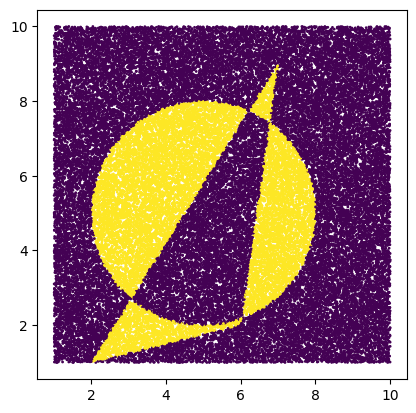

In [83]:
plt.scatter(points[0], points[1], c=in_area, s=1)
plt.gca().set_aspect('equal')
plt.show()

In [154]:
def die_roll():
    return random.randint(1, 6)

def game(n, counts=1000):
    count = 0
    die_rolls = []
    rolls = []

    for _ in range(counts):
        die_rolls.append(die_roll())

    for roll in die_rolls:
        count += 1
        rolls.append(roll)
        if count >= 3:
            rolls = rolls[-3:]
            sum = np.sum(rolls)
            if sum % 2 == 0 and rolls[-2] <= n:
                return count

In [180]:
expected_num = []
mean = []
for n in range(1, 7):
    for _ in range(1000):
        expected_num.append(game(n))
    mean.append(np.mean(expected_num))
mean

[np.float64(14.22),
 np.float64(11.0395),
 np.float64(9.393666666666666),
 np.float64(8.289),
 np.float64(7.496),
 np.float64(6.899166666666667)]

<BarContainer object of 6 artists>

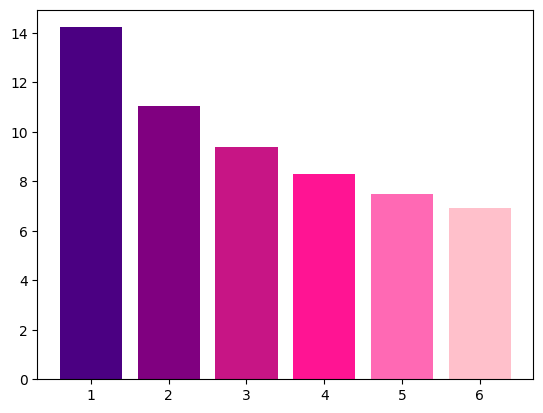

In [186]:
plt.bar([n for n in range(1, 7)], mean, color=["indigo", "purple", "mediumvioletred", "deeppink", "hotpink", "pink"])

In [408]:
def same_birthday_prob(n, k):
    birthdays = []
    probability = 0
    counts = []
    for _ in range(1000):
        birthdays = [random.randint(1, 365) for _ in range(n)]
        days, unique_counts = np.unique(birthdays, return_counts=True)
        counts.append(np.sum([unique_counts > 1]))

    counts = np.array(counts)
    return np.sum(counts > k) / 10


<BarContainer object of 69 artists>

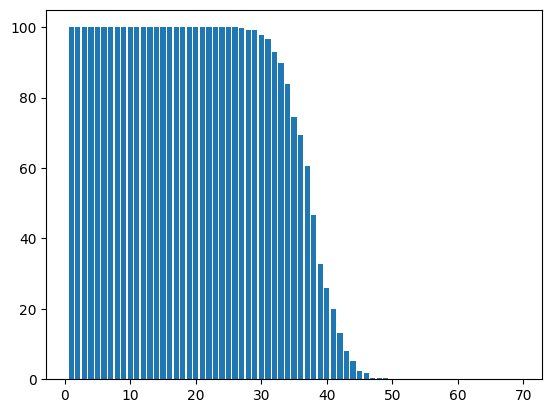

In [418]:
prob = []
for k in range(1, 70):
    prob.append(same_birthday_prob(n=200, k=k))
plt.bar([k for k in range(1, 70)], prob)

<BarContainer object of 364 artists>

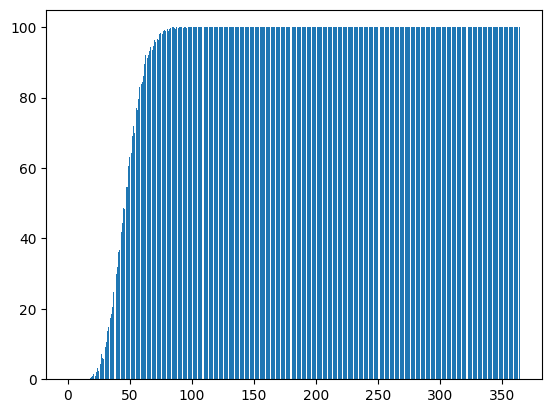

In [429]:
prob = []
for n in range(1, 365):
    prob.append(same_birthday_prob(n=n, k=2))
plt.bar([n for n in range(1, 365)], prob)

In [431]:
prob_arr = np.array(prob)
np.where(prob_arr>50)[0][0]

np.int64(46)

In [ ]:
class IteratedFunctionSystem:
    def __init__(self, matrices, weights, start):
        self.matrices = matrices
        self.weights = weights
        self.start = start

    def update_position(self, pos):
        M, = random.choices(self.matrices, weights=self.weights)
        A = M[:, :2]
        b = M[:, 2]
        return A @ pos + b

    def make_trajectory(self, iterations):
        x, y = self.start
        xs, ys = [], []
        for i in range(iterations):
            xs.append(x)
            ys.append(y)
            x, y = self.update_position(x, y)
        return xs, ys

    def draw(self, iterations=100):
        xs, ys = self.make_trajectory(iterations)
        plt.scatter(xs, ys, color='green', s=1)
        plt.title(f"{iterations} iterations")
        plt.xlabel("X")
        plt.ylabel("Y")
        plt.show()